In [4]:
from deepface import DeepFace
import matplotlib.pyplot as plt
import pandas as pd
import cv2

In [11]:
objs = DeepFace.analyze(img_path = "sss.png", 
        actions = ['age','emotion']
)

Action: emotion: 100%|██████████| 2/2 [00:00<00:00,  5.38it/s]


In [13]:
from glob import glob

In [14]:
def plot_img_emotion(img,emo_df,figsize=(15,5)):
    img=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    fig,axs = plt.subplots(1,2,figsize=figsize)
    axs[0].axis("off")
    axs[0].imshow(img)
    emo_df.sort_values("prediction").plot(kind="barh",figsize=figsize,ax=axs[1])
    plt.show()

In [17]:
backends = ['opencv', 'ssd', 'dlib', 'mtcnn', 'retinaface','mediapipe']

Action: race: 100%|██████████| 4/4 [00:00<00:00, 15.94it/s]  


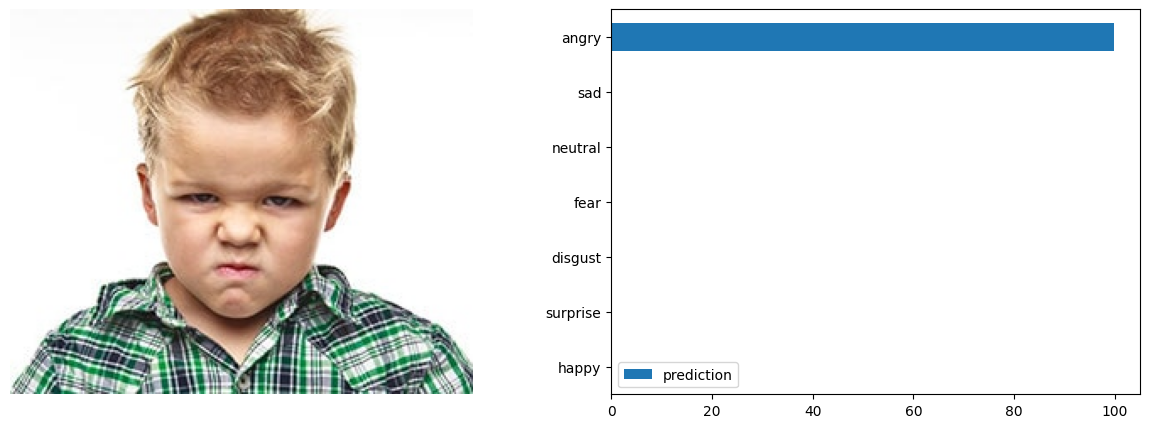

Action: race: 100%|██████████| 4/4 [00:00<00:00, 14.78it/s]  


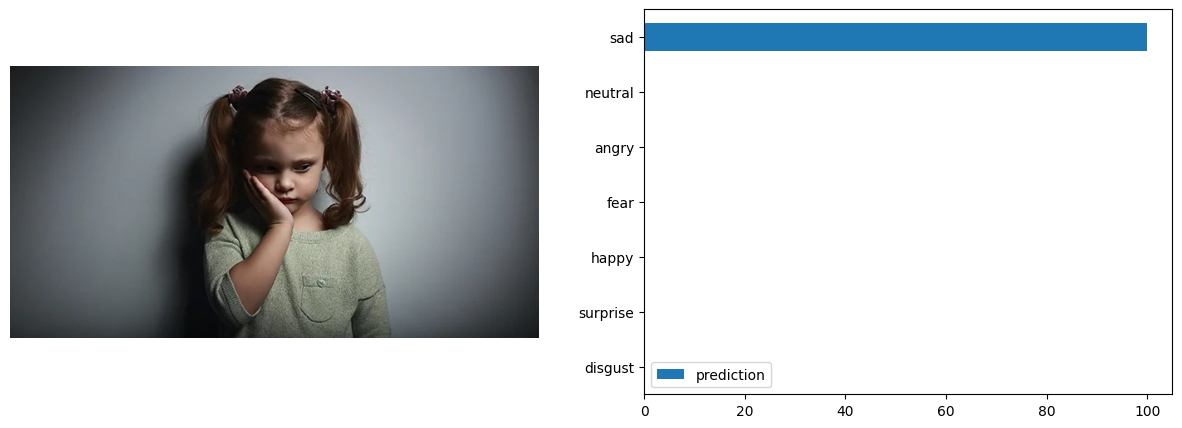

Action: race: 100%|██████████| 4/4 [00:00<00:00, 16.12it/s]  


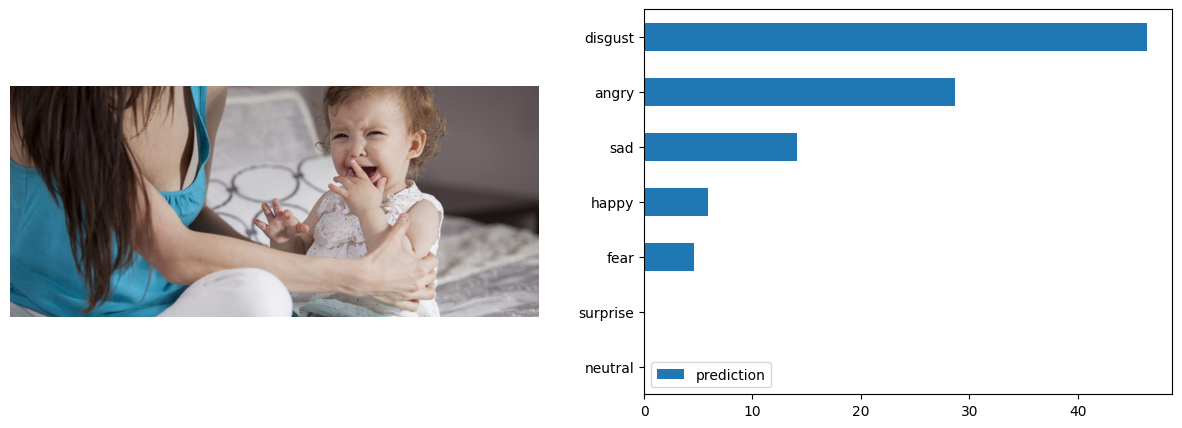

Action: race: 100%|██████████| 4/4 [00:00<00:00, 15.93it/s]  


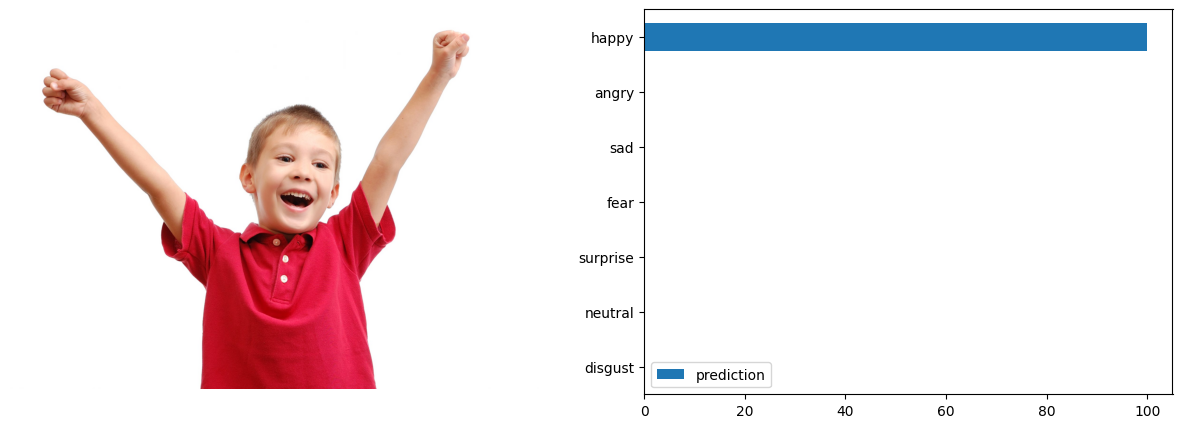

Action: race: 100%|██████████| 4/4 [00:00<00:00, 15.98it/s]  


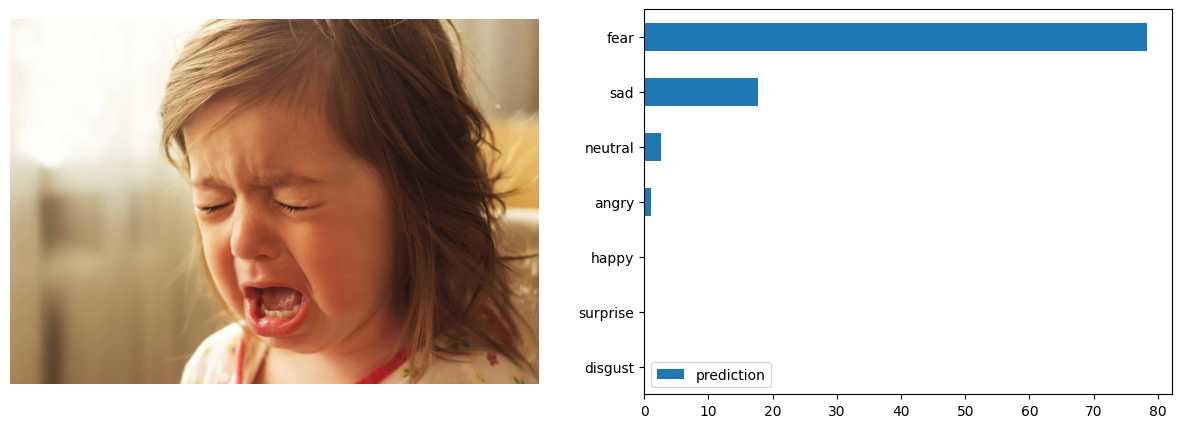

In [28]:
import cv2
imgs = glob("TheChampsEmotions/*")

for img_path in imgs:
    demographies = DeepFace.analyze(img_path=img_path, detector_backend=backends[4])
    for demography in demographies:
        img = cv2.imread(img_path)
        emo_df = pd.DataFrame(demography["emotion"], index=[0]).T.rename(columns={0: "prediction"})
        plot_img_emotion(img, emo_df)
        plt.show()

In [ ]:
DeepFace.stream(db_path='TheChampsEmotions',source=0)

24-05-02 16:12:30 - facial recognition model VGG-Face is just built
24-05-02 16:12:30 - Age model is just built
24-05-02 16:12:30 - Gender model is just built
24-05-02 16:12:30 - Emotion model is just built


Finding representations: 100%|██████████| 4/4 [00:01<00:00,  2.20it/s]


24-05-02 16:12:32 - Representations stored in TheChampsEmotions/representations_vgg_face.pkl file.
24-05-02 16:12:33 - find function lasts 2.086317300796509 seconds


In [5]:
import cv2
import DeepFace

def stream_faces(db_path='A', source=0):
    cap = cv2.VideoCapture(source)
    deep_face_stream = None
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        # Your facial recognition processing code here
        
        if deep_face_stream is None:
            deep_face_stream = DeepFace.stream(db_path='TheChampsEmotions', source=0)
        
        cv2.imshow('Face Stream', frame)
        
        key = cv2.waitKey(1)
        if key == 27:  # ASCII code for Escape key
            break
    
    if deep_face_stream is not None:
        deep_face_stream.stop()
    
    cap.release()
    cv2.destroyAllWindows()

# Example usage:
stream_faces()


24-05-02 16:18:05 - facial recognition model VGG-Face is just built
24-05-02 16:18:06 - Age model is just built
24-05-02 16:18:06 - Gender model is just built
24-05-02 16:18:07 - Emotion model is just built
24-05-02 16:18:07 - There are 1 representations found in representations_vgg_face.pkl
24-05-02 16:18:07 - find function lasts 0.26555848121643066 seconds


KeyboardInterrupt: 